In [3]:
 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the sales dataset
df = pd.read_csv("sales_data.csv")

# Display the first 5 records
df.head()


,product_id,category,price,units_sold,date
0,P001,Laptop,51334.43,11,2025-11-21
1,P002,Laptop,2488.36,11,2025-11-21
2,P003,Laptop,22364.83,6,2025-11-21
3,P004,Laptop,18245.25,21,2025-11-21
4,P005,Laptop,59049.46,8,2025-11-21


In [3]:

# Check dataset information
print("===== DATASET INFORMATION =====")
df.info()

# Check missing values
print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

# Check duplicate records
print("\n===== DUPLICATE RECORDS =====")
print(df.duplicated().sum())

# Check dataset dimensions
print("\n===== DATASET SHAPE =====")
print(df.shape)


===== DATASET INFORMATION =====
<class 'pandas.DataFrame'>
RangeIndex: 18250 entries, 0 to 18249
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   product_id  18250 non-null  str    
 1   category    18250 non-null  str    
 2   price       18250 non-null  float64
 3   units_sold  18250 non-null  int64  
 4   date        18250 non-null  str    
dtypes: float64(1), int64(1), str(3)
memory usage: 713.0 KB

===== MISSING VALUES =====
product_id    0
category      0
price         0
units_sold    0
date          0
dtype: int64

===== DUPLICATE RECORDS =====
0

===== DATASET SHAPE =====
(18250, 5)


In [4]:

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Check and handle missing values
df = df.dropna()

# Calculate revenue
df["revenue"] = df["price"] * df["units_sold"]

# Display cleaned dataset
print("===== CLEANED DATASET =====")
print(df.head())

print("\nFinal Dataset Shape:", df.shape)

===== CLEANED DATASET =====
  product_id category     price  units_sold       date    revenue
0       P001   Laptop  51334.43          11 2025-11-21  564678.73
1       P002   Laptop   2488.36          11 2025-11-21   27371.96
2       P003   Laptop  22364.83           6 2025-11-21  134188.98
3       P004   Laptop  18245.25          21 2025-11-21  383150.25
4       P005   Laptop  59049.46           8 2025-11-21  472395.68

Final Dataset Shape: (18250, 6)


In [5]:

# ===== SUMMARY STATISTICS =====

print("===== NUMERICAL SUMMARY =====")
print(df[["price", "units_sold", "revenue"]].describe())

print("\n===== CATEGORY SUMMARY =====")
print(df.groupby("category").agg(
    total_units=("units_sold", "sum"),
    average_price=("price", "mean"),
    total_revenue=("revenue", "sum")
).round(2))

print("\n===== PRICING INSIGHTS =====")
print("Minimum Price:", round(df["price"].min(), 2))
print("Maximum Price:", round(df["price"].max(), 2))
print("Average Price:", round(df["price"].mean(), 2))
print("Median Price:", round(df["price"].median(), 2))


===== NUMERICAL SUMMARY =====
              price    units_sold       revenue
count  18250.000000  18250.000000  1.825000e+04
mean   36329.397400     15.015781  5.472048e+05
std    23082.747301      8.893194  5.147244e+05
min     1016.650000      0.000000  0.000000e+00
25%    17881.720000      7.000000  1.185862e+05
50%    37359.265000     15.000000  3.873758e+05
75%    56002.080000     23.000000  8.566174e+05
max    77862.700000     30.000000  2.335881e+06

===== CATEGORY SUMMARY =====
            total_units  average_price  total_revenue
category                                             
Headphones        54419       39726.72   2.191981e+09
Keyboard          54750       24030.07   1.317926e+09
Laptop            55764       32353.15   1.799935e+09
Monitor           54494       55066.91   2.998966e+09
Smartphone        54611       30470.14   1.677680e+09

===== PRICING INSIGHTS =====
Minimum Price: 1016.65
Maximum Price: 77862.7
Average Price: 36329.4
Median Price: 37359.26


In [4]:

# ===== OUTLIER DETECTION =====

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["price"] < lower_limit) |
    (df["price"] > upper_limit)
]

print("===== PRICE OUTLIER ANALYSIS =====")
print("Lower Limit:", round(lower_limit, 2))
print("Upper Limit:", round(upper_limit, 2))
print("Number of Price Outliers:", len(outliers))

print("\n===== OUTLIER EXAMPLES =====")
print(outliers[["product_id", "category", "price"]].head(10))

===== PRICE OUTLIER ANALYSIS =====
Lower Limit: -39298.82
Upper Limit: 113182.62
Number of Price Outliers: 0

===== OUTLIER EXAMPLES =====
Empty DataFrame
Columns: [product_id, category, price]
Index: []


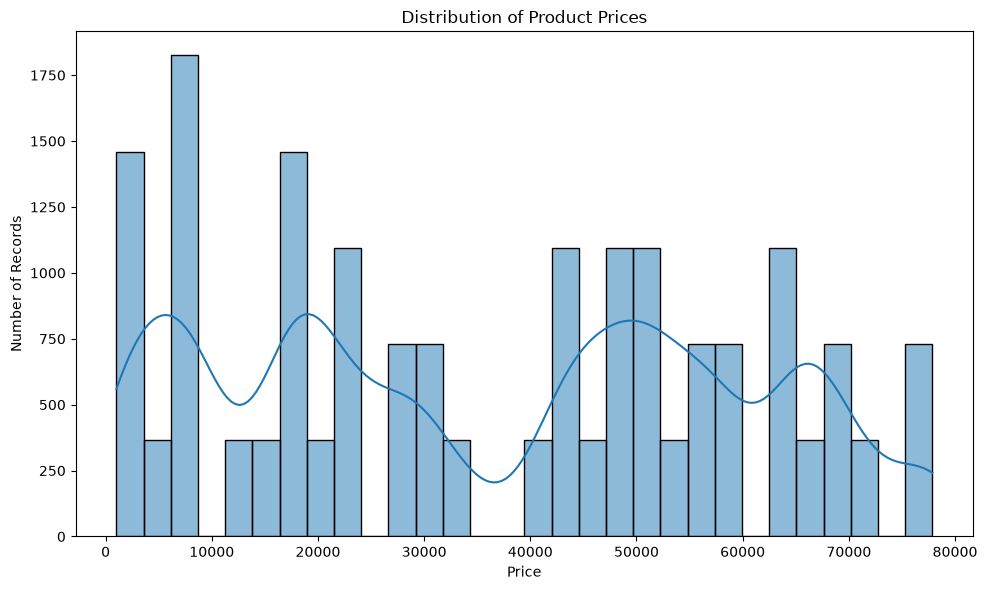

In [7]:
# Price Distribution

plt.figure(figsize=(10, 6))

sns.histplot(df["price"], bins=30, kde=True)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("price_distribution.png", dpi=300)
plt.show()

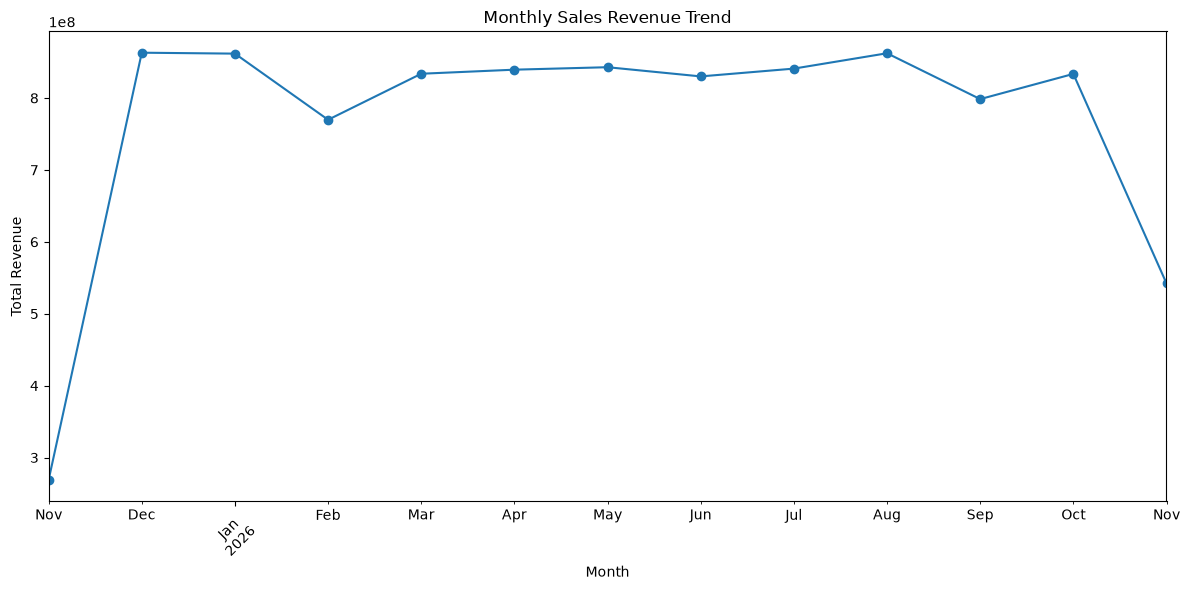

In [8]:
# ===== MONTHLY SALES TREND =====

df["month"] = df["date"].dt.to_period("M")

monthly_sales = df.groupby("month")["revenue"].sum()

plt.figure(figsize=(12, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("monthly_sales_trend.png", dpi=300)
plt.show()

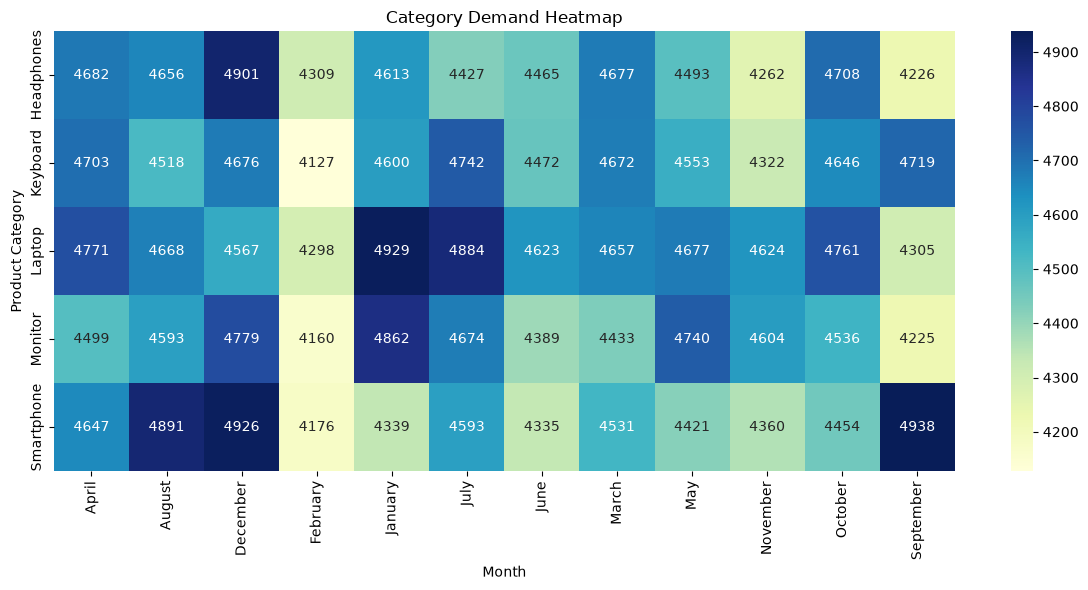

In [9]:
# ===== CATEGORY DEMAND HEATMAP =====

df["month"] = df["date"].dt.month_name()

heatmap_data = df.pivot_table(
    index="category",
    columns="month",
    values="units_sold",
    aggfunc="sum"
)

plt.figure(figsize=(12, 6))

sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu")

plt.title("Category Demand Heatmap")
plt.xlabel("Month")
plt.ylabel("Product Category")

plt.tight_layout()
plt.savefig("category_demand_heatmap.png", dpi=300)
plt.show()